# AI-Powered Network Intrusion Detection System

## Notebook 05 – Random Forest Intrusion Detection Model

**Author:** Jithesh  
**Role:** Member A – ML & Data Engineer  
**Dataset:** CICIDS-2017  
**Model:** Random Forest Classifier

---

### Purpose

The purpose of this notebook is to train and evaluate a Random Forest intrusion detection model using the validated and persisted model-preparation artifacts generated by Notebook 04.

The notebook focuses on reproducible model training, resource-aware hyperparameter tuning, comprehensive evaluation, and persistence of the final trained model for subsequent ensemble development and backend integration.

---

### Notebook Objective

This notebook continues from Notebook 04 and uses the persisted model-ready CICIDS-2017 training and testing artifacts.

The main objectives are to:

1. Load and verify the persisted model-preparation artifacts.
2. Establish a resource-aware Random Forest training strategy.
3. Train a baseline Random Forest classifier.
4. Investigate and tune important Random Forest hyperparameters.
5. Train the final selected Random Forest model.
6. Evaluate the model using accuracy, precision, recall, F1-score, and confusion matrix.
7. Analyze feature importance and model behavior.
8. Persist the trained model and associated metadata for downstream use.
9. Validate the persisted model and establish a reproducible handoff for subsequent model development.

The persisted model-preparation artifacts generated by Notebook 04 are treated as read-only inputs and are not modified by this notebook.

### 5.1 Environment Setup

This section initializes the Colab environment, imports the libraries required for Random Forest model training and evaluation, and defines the project storage paths.

The notebook reuses the established Google Drive project structure from previous notebooks.

A single environment setup cell is used so that, after a Colab runtime restart, the environment and project paths can be restored without rerunning the complete notebook.

In [29]:
# ============================================================
# 5.1 Environment Setup
# ============================================================

import os
import json
import gc
import joblib
import numpy as np
import pandas as pd

from pathlib import Path

# Machine learning
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Visualization
import matplotlib.pyplot as plt

# Google Drive
from google.colab import drive
drive.mount("/content/drive")

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_PATH = "/content/drive/MyDrive/AI-Network-Intrusion-Detection-System"

DATA_PATH = os.path.join(PROJECT_PATH, "data")
RAW_DATA_PATH = os.path.join(DATA_PATH, "raw")
PROCESSED_DATA_PATH = os.path.join(DATA_PATH, "processed")

OUTPUTS_PATH = os.path.join(PROJECT_PATH, "outputs")
MODELS_PATH = os.path.join(PROJECT_PATH, "trained_models")

# Model-preparation artifacts from Notebook 04
MODEL_PREP_PATH = os.path.join(
    OUTPUTS_PATH,
    "model_preparation"
)

# Create model directory if required
os.makedirs(MODELS_PATH, exist_ok=True)

# ------------------------------------------------------------
# Display environment information
# ------------------------------------------------------------

print("=" * 70)
print("ENVIRONMENT SETUP")
print("=" * 70)

print("\nProject path:")
print(PROJECT_PATH)

print("\nModel-preparation path:")
print(MODEL_PREP_PATH)

print("\nModels path:")
print(MODELS_PATH)

print("\nEnvironment setup completed successfully.")
print("=" * 70)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ENVIRONMENT SETUP

Project path:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System

Model-preparation path:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/model_preparation

Models path:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/trained_models

Environment setup completed successfully.


### 5.2 Load Model-Preparation Artifacts

**Purpose:**

Load the persisted model-ready training and testing artifacts generated by Notebook 04.

The artifacts include the scaled feature matrices, target arrays, fitted `StandardScaler`, and feature metadata.

The persisted arrays are loaded using NumPy memory mapping where possible to reduce unnecessary RAM consumption in the Colab runtime. The model-preparation artifacts are treated as read-only inputs and will not be modified.

The training and testing split established in Notebook 04 is reused directly. No additional train-test splitting or feature scaling is performed in this notebook.

In [30]:
# ============================================================
# 5.2 Load Model-Preparation Artifacts
# ============================================================

print("=" * 70)
print("LOADING MODEL-PREPARATION ARTIFACTS")
print("=" * 70)

# ------------------------------------------------------------
# Define artifact paths
# ------------------------------------------------------------

X_TRAIN_PATH = os.path.join(
    MODEL_PREP_PATH,
    "X_train_scaled.npy"
)

X_TEST_PATH = os.path.join(
    MODEL_PREP_PATH,
    "X_test_scaled.npy"
)

Y_TRAIN_PATH = os.path.join(
    MODEL_PREP_PATH,
    "y_train.npy"
)

Y_TEST_PATH = os.path.join(
    MODEL_PREP_PATH,
    "y_test.npy"
)

SCALER_PATH = os.path.join(
    MODEL_PREP_PATH,
    "standard_scaler.joblib"
)

FEATURE_METADATA_PATH = os.path.join(
    MODEL_PREP_PATH,
    "feature_metadata.json"
)

# ------------------------------------------------------------
# Verify required artifacts exist
# ------------------------------------------------------------

required_artifacts = [
    X_TRAIN_PATH,
    X_TEST_PATH,
    Y_TRAIN_PATH,
    Y_TEST_PATH,
    SCALER_PATH,
    FEATURE_METADATA_PATH
]

print("\nChecking required artifacts:")

for artifact in required_artifacts:
    if not os.path.exists(artifact):
        raise FileNotFoundError(
            f"Required artifact not found: {artifact}"
        )

    print("✓", os.path.basename(artifact))

# ------------------------------------------------------------
# Load feature matrices using memory mapping
# ------------------------------------------------------------

X_train = np.load(
    X_TRAIN_PATH,
    mmap_mode="r"
)

X_test = np.load(
    X_TEST_PATH,
    mmap_mode="r"
)

# Target arrays are small enough to load normally
y_train = np.load(Y_TRAIN_PATH)
y_test = np.load(Y_TEST_PATH)

# Load scaler and metadata
scaler = joblib.load(SCALER_PATH)

with open(FEATURE_METADATA_PATH, "r") as f:
    feature_metadata = json.load(f)

# ------------------------------------------------------------
# Display loaded artifact information
# ------------------------------------------------------------

print("\nArtifacts loaded successfully.")

print("\nFeature matrices:")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nTarget arrays:")
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nData types:")
print("X_train:", X_train.dtype)
print("X_test:", X_test.dtype)
print("y_train:", y_train.dtype)
print("y_test:", y_test.dtype)

print("\nMemory mapping:")
print("X_train:", type(X_train).__name__)
print("X_test:", type(X_test).__name__)

print("\nFeature metadata:")
print("Dataset:", feature_metadata["dataset"])
print("Number of features:", feature_metadata["number_of_features"])
print("Target column:", feature_metadata["target_column"])

print("\nModel-preparation artifacts loaded successfully.")
print("=" * 70)

LOADING MODEL-PREPARATION ARTIFACTS

Checking required artifacts:
✓ X_train_scaled.npy
✓ X_test_scaled.npy
✓ y_train.npy
✓ y_test.npy
✓ standard_scaler.joblib
✓ feature_metadata.json

Artifacts loaded successfully.

Feature matrices:
X_train shape: (2264594, 63)
X_test shape: (566149, 63)

Target arrays:
y_train shape: (2264594,)
y_test shape: (566149,)

Data types:
X_train: float32
X_test: float32
y_train: int8
y_test: int8

Memory mapping:
X_train: memmap
X_test: memmap

Feature metadata:
Dataset: CICIDS2017
Number of features: 63
Target column: Target

Model-preparation artifacts loaded successfully.


### 5.2.1 Validate Model-Ready Data

Before model training, the persisted model-preparation artifacts are validated to ensure that the training and testing data are structurally consistent and suitable for Random Forest training.

The validation includes:

- Sample and feature dimension checks
- Training/testing target alignment
- Class-count and class-distribution analysis
- Verification of finite feature values
- Verification of the persisted scaler and feature metadata
- Basic statistical checks on the standardized training features

The validation is performed without modifying the persisted artifacts.

In [31]:
# ============================================================
# 5.2.1 Validate Model-Ready Data
# ============================================================

print("=" * 70)
print("MODEL-READY DATA VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Shape and alignment checks
# ------------------------------------------------------------

assert X_train.ndim == 2
assert X_test.ndim == 2

assert y_train.ndim == 1
assert y_test.ndim == 1

assert X_train.shape[0] == y_train.shape[0]
assert X_test.shape[0] == y_test.shape[0]

assert X_train.shape[1] == X_test.shape[1]

print("\nShape validation: PASSED")
print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])
print("Features        :", X_train.shape[1])

# ------------------------------------------------------------
# 2. Feature metadata validation
# ------------------------------------------------------------

assert X_train.shape[1] == feature_metadata["number_of_features"]
assert X_test.shape[1] == feature_metadata["number_of_features"]

assert scaler.n_features_in_ == X_train.shape[1]

print("Feature metadata validation: PASSED")
print("Scaler feature count:", scaler.n_features_in_)

# ------------------------------------------------------------
# 3. Class distribution
# ------------------------------------------------------------

train_classes, train_counts = np.unique(
    y_train,
    return_counts=True
)

test_classes, test_counts = np.unique(
    y_test,
    return_counts=True
)

print("\nClass distribution:")
print("-" * 70)

print(f"{'Class':<10}{'Train':>15}{'Train %':>15}{'Test':>15}{'Test %':>15}")

train_total = len(y_train)
test_total = len(y_test)

for cls in train_classes:

    train_count = train_counts[
        np.where(train_classes == cls)[0][0]
    ]

    if cls in test_classes:
        test_count = test_counts[
            np.where(test_classes == cls)[0][0]
        ]
    else:
        test_count = 0

    train_pct = (train_count / train_total) * 100
    test_pct = (test_count / test_total) * 100

    print(
        f"{int(cls):<10}"
        f"{train_count:>15,}"
        f"{train_pct:>14.4f}%"
        f"{test_count:>15,}"
        f"{test_pct:>14.4f}%"
    )

print("-" * 70)
print("Number of training classes:", len(train_classes))
print("Number of testing classes :", len(test_classes))

# ------------------------------------------------------------
# 4. Verify train/test contain the same classes
# ------------------------------------------------------------

assert np.array_equal(
    np.sort(train_classes),
    np.sort(test_classes)
)

print("\nClass consistency check: PASSED")
print("All classes are represented in both training and testing sets.")

# ------------------------------------------------------------
# 5. Check feature values for NaN / infinity
# ------------------------------------------------------------

def check_finite_memmap(array, chunk_size=100_000):

    for start in range(0, array.shape[0], chunk_size):

        end = min(start + chunk_size, array.shape[0])

        chunk = array[start:end]

        if not np.isfinite(chunk).all():
            return False

    return True


train_finite = check_finite_memmap(X_train)
test_finite = check_finite_memmap(X_test)

assert train_finite
assert test_finite

print("\nFinite-value check: PASSED")
print("No NaN or infinite values detected.")

# ------------------------------------------------------------
# 6. Check standardized training statistics
# ------------------------------------------------------------

# Process in chunks to avoid creating large temporary arrays.
feature_sum = np.zeros(X_train.shape[1], dtype=np.float64)
feature_sq_sum = np.zeros(X_train.shape[1], dtype=np.float64)

for start in range(0, X_train.shape[0], 100_000):

    end = min(start + 100_000, X_train.shape[0])

    chunk = X_train[start:end].astype(
        np.float64,
        copy=False
    )

    feature_sum += chunk.sum(axis=0)
    feature_sq_sum += np.square(chunk).sum(axis=0)

n_samples = X_train.shape[0]

train_means = feature_sum / n_samples

train_variances = (
    feature_sq_sum / n_samples
) - np.square(train_means)

train_stds = np.sqrt(
    np.maximum(train_variances, 0)
)

max_abs_mean = np.max(np.abs(train_means))

# Ignore constant features when checking unit variance.
non_constant = train_stds > 1e-12

if np.any(non_constant):
    max_std_deviation = np.max(
        np.abs(train_stds[non_constant] - 1)
    )
else:
    max_std_deviation = 0.0

print("\nStandardization check:")
print("Maximum absolute training mean:",
      max_abs_mean)

print("Maximum deviation from unit standard deviation:",
      max_std_deviation)

# ------------------------------------------------------------
# 7. Final validation summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL-READY DATA VALIDATION SUMMARY")
print("=" * 70)

print("✓ Shape and alignment checks: PASSED")
print("✓ Feature metadata check: PASSED")
print("✓ Class consistency check: PASSED")
print("✓ Finite-value check: PASSED")
print("✓ Standardization check: PASSED")

print("\nModel-ready data validation completed successfully.")
print("=" * 70)

MODEL-READY DATA VALIDATION

Shape validation: PASSED
Training samples: 2264594
Testing samples : 566149
Features        : 63
Feature metadata validation: PASSED
Scaler feature count: 63

Class distribution:
----------------------------------------------------------------------
Class               Train        Train %           Test         Test %
0               1,818,477       80.3004%        454,620       80.3004%
1                   1,573        0.0695%            393        0.0694%
2                 102,421        4.5227%         25,606        4.5228%
3                   8,234        0.3636%          2,059        0.3637%
4                 184,858        8.1630%         46,215        8.1630%
5                   4,399        0.1943%          1,100        0.1943%
6                   4,637        0.2048%          1,159        0.2047%
7                   6,350        0.2804%          1,588        0.2805%
8                       9        0.0004%              2        0.0004%
9          

### 5.3 Class Imbalance Strategy

The validated CICIDS2017 model-preparation dataset contains 15 target classes with severe class imbalance.

The majority class represents approximately 80.3% of the training data, while several minority classes contain only a very small number of training samples.

Direct oversampling of the complete training dataset using SMOTE is therefore not selected as the default strategy for Random Forest training. Applying synthetic oversampling to the entire dataset would substantially increase memory and computational requirements, particularly when attempting to compensate for the highly dominant majority class.

Instead, the initial Random Forest model will use class-weighted learning through:

`class_weight="balanced_subsample"`

This allows individual trees to account for the class distribution without physically creating a substantially larger training dataset.

The model will be evaluated using class-sensitive metrics, particularly macro-averaged precision, recall, and F1-score, in addition to overall accuracy and weighted metrics.

SMOTE remains a possible future experimental strategy if further investigation demonstrates that class weighting alone is insufficient.

### 5.3.1 Quantify Class Imbalance

The class distribution is quantified using the training targets to determine the relative representation of each attack class.

The imbalance ratio is calculated as the number of samples in the majority class divided by the number of samples in the minority class.

This provides a quantitative basis for selecting class-weighted learning and for interpreting the model's per-class evaluation results.

In [32]:
# ============================================================
# 5.3.1 Quantify Class Imbalance
# ============================================================

print("=" * 70)
print("CLASS IMBALANCE ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Calculate class counts
# ------------------------------------------------------------

classes, counts = np.unique(
    y_train,
    return_counts=True
)

majority_index = np.argmax(counts)
minority_index = np.argmin(counts)

majority_class = classes[majority_index]
majority_count = counts[majority_index]

minority_class = classes[minority_index]
minority_count = counts[minority_index]

imbalance_ratio = majority_count / minority_count

print("\nNumber of classes:", len(classes))

print(
    f"Majority class: {majority_class} "
    f"({majority_count:,} samples)"
)

print(
    f"Minority class: {minority_class} "
    f"({minority_count:,} samples)"
)

print(
    f"Majority/minority ratio: "
    f"{imbalance_ratio:,.2f}:1"
)

# ------------------------------------------------------------
# Display classes sorted by sample count
# ------------------------------------------------------------

class_distribution = pd.DataFrame({
    "Class": classes,
    "Samples": counts,
    "Percentage": (counts / len(y_train)) * 100
}).sort_values(
    "Samples",
    ascending=True
)

print("\nClass distribution from smallest to largest:")
print(class_distribution.to_string(index=False))

# ------------------------------------------------------------
# Identify extremely rare classes
# ------------------------------------------------------------

rare_threshold = 100

rare_classes = class_distribution[
    class_distribution["Samples"] < rare_threshold
]

print(
    f"\nClasses with fewer than "
    f"{rare_threshold} training samples:"
)

if len(rare_classes) > 0:
    print(rare_classes.to_string(index=False))
else:
    print("None")

# ------------------------------------------------------------
# Decision summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASS IMBALANCE DECISION")
print("=" * 70)

print(
    "Default strategy: "
    "class_weight='balanced_subsample'"
)

print(
    "SMOTE: Not applied to the complete training dataset "
    "at this stage."
)

print(
    "Evaluation priority: "
    "Macro F1, Macro Recall, and per-class performance."
)

print("=" * 70)

CLASS IMBALANCE ANALYSIS

Number of classes: 15
Majority class: 0 (1,818,477 samples)
Minority class: 8 (9 samples)
Majority/minority ratio: 202,053.00:1

Class distribution from smallest to largest:
 Class  Samples  Percentage
     8        9    0.000397
    13       17    0.000751
     9       29    0.001281
    14      522    0.023050
    12     1206    0.053255
     1     1573    0.069461
     5     4399    0.194251
     6     4637    0.204761
    11     4718    0.208338
     7     6350    0.280403
     3     8234    0.363597
     2   102421    4.522709
    10   127144    5.614428
     4   184858    8.162964
     0  1818477   80.300354

Classes with fewer than 100 training samples:
 Class  Samples  Percentage
     8        9    0.000397
    13       17    0.000751
     9       29    0.001281

CLASS IMBALANCE DECISION
Default strategy: class_weight='balanced_subsample'
SMOTE: Not applied to the complete training dataset at this stage.
Evaluation priority: Macro F1, Macro Recall, and

### 5.4 Random Forest Baseline Configuration

A Random Forest classifier is selected as the first supervised intrusion-detection model.

The baseline configuration is designed to establish a reproducible reference model before hyperparameter tuning.

Because the training dataset contains more than 2.2 million samples and exhibits severe class imbalance, the model will use class-weighted learning rather than full-dataset oversampling.

The initial configuration uses:

- 100 decision trees
- `class_weight="balanced_subsample"`
- `max_features="sqrt"`
- unlimited tree depth initially
- all available CPU cores through `n_jobs=-1`
- fixed `random_state=42` for reproducibility

Before committing to the full baseline training run, a controlled training benchmark will be performed to verify runtime and memory behavior in the Colab environment.

In [33]:
# ============================================================
# 5.4.1 Define Random Forest Baseline
# ============================================================

from sklearn.ensemble import RandomForestClassifier

print("=" * 70)
print("RANDOM FOREST BASELINE CONFIGURATION")
print("=" * 70)

RF_RANDOM_STATE = 42

rf_baseline = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",
    max_features="sqrt",
    max_depth=None,
    n_jobs=-1,
    random_state=RF_RANDOM_STATE
)

print("\nBaseline configuration:")
print("n_estimators       :", rf_baseline.n_estimators)
print("class_weight       :", rf_baseline.class_weight)
print("max_features       :", rf_baseline.max_features)
print("max_depth          :", rf_baseline.max_depth)
print("n_jobs             :", rf_baseline.n_jobs)
print("random_state       :", rf_baseline.random_state)

print("\nModel object created successfully.")
print("=" * 70)

RANDOM FOREST BASELINE CONFIGURATION

Baseline configuration:
n_estimators       : 100
class_weight       : balanced_subsample
max_features       : sqrt
max_depth          : None
n_jobs             : -1
random_state       : 42

Model object created successfully.


### 5.4.2 Training Resource Benchmark

Before training the complete Random Forest, a controlled benchmark is performed to estimate training time and memory behavior in the current Colab runtime.

A stratified subset of the training data is used so that the benchmark retains representation from all target classes.

The benchmark uses a reduced number of trees and is intended only for resource estimation. It is not used for final model evaluation or saved as the production Random Forest.

The full training configuration will be selected after reviewing the observed runtime and memory behavior.

In [34]:
# ============================================================
# 5.4.2 Random Forest Training Resource Benchmark
# ============================================================

import time
import gc

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

print("=" * 70)
print("RANDOM FOREST TRAINING RESOURCE BENCHMARK")
print("=" * 70)

# ------------------------------------------------------------
# Benchmark configuration
# ------------------------------------------------------------

BENCHMARK_SAMPLES = 200_000
BENCHMARK_TREES = 10
BENCHMARK_RANDOM_STATE = 42

print("\nBenchmark configuration:")
print("Samples:", f"{BENCHMARK_SAMPLES:,}")
print("Trees  :", BENCHMARK_TREES)
print("Strategy: Stratified sampling")
print("Class weighting: balanced_subsample")

# ------------------------------------------------------------
# Create stratified benchmark subset
# ------------------------------------------------------------

# train_test_split with a dummy test fraction gives us
# a stratified subset of the training data.
X_bench, _, y_bench, _ = train_test_split(
    X_train,
    y_train,
    train_size=BENCHMARK_SAMPLES,
    stratify=y_train,
    random_state=BENCHMARK_RANDOM_STATE
)

print("\nBenchmark subset created.")
print("X_bench shape:", X_bench.shape)
print("y_bench shape:", y_bench.shape)

print(
    "Number of classes represented:",
    len(np.unique(y_bench))
)

assert len(np.unique(y_bench)) == len(np.unique(y_train))

# ------------------------------------------------------------
# Train benchmark model
# ------------------------------------------------------------

rf_benchmark = RandomForestClassifier(
    n_estimators=BENCHMARK_TREES,
    class_weight="balanced_subsample",
    max_features="sqrt",
    max_depth=None,
    n_jobs=-1,
    random_state=BENCHMARK_RANDOM_STATE
)

print("\nStarting benchmark training...")
print("Do not interrupt the cell while the model is fitting.")

start_time = time.perf_counter()

rf_benchmark.fit(
    X_bench,
    y_bench
)

elapsed_time = time.perf_counter() - start_time

# ------------------------------------------------------------
# Report benchmark results
# ------------------------------------------------------------

print("\nBenchmark training completed.")

print(
    f"Training time: {elapsed_time:.2f} seconds "
    f"({elapsed_time / 60:.2f} minutes)"
)

print(
    "Trees trained:",
    len(rf_benchmark.estimators_)
)

print(
    "Classes learned:",
    len(rf_benchmark.classes_)
)

# ------------------------------------------------------------
# Clean up benchmark objects
# ------------------------------------------------------------

del X_bench
del y_bench
del rf_benchmark

gc.collect()

print("\nBenchmark objects released from memory.")
print("=" * 70)

RANDOM FOREST TRAINING RESOURCE BENCHMARK

Benchmark configuration:
Samples: 200,000
Trees  : 10
Strategy: Stratified sampling
Class weighting: balanced_subsample

Benchmark subset created.
X_bench shape: (200000, 63)
y_bench shape: (200000,)
Number of classes represented: 15

Starting benchmark training...
Do not interrupt the cell while the model is fitting.

Benchmark training completed.
Training time: 4.23 seconds (0.07 minutes)
Trees trained: 10
Classes learned: 15

Benchmark objects released from memory.


### 5.4.3 Train the Baseline Random Forest

The baseline Random Forest is trained using the complete model-ready training dataset generated by Notebook 04.

The previously established stratified train-test split is reused without modification.

The model uses class-weighted learning through `balanced_subsample` to compensate for the severe class imbalance identified during the investigation.

The baseline model is trained with 100 trees and a fixed random seed to ensure reproducibility.

This model serves as the reference point for subsequent evaluation and hyperparameter tuning.

In [35]:
# ============================================================
# 5.4.3 Train Baseline Random Forest
# ============================================================

import time
import gc

print("=" * 70)
print("BASELINE RANDOM FOREST TRAINING")
print("=" * 70)

print("\nTraining data:")
print("Samples :", f"{X_train.shape[0]:,}")
print("Features:", X_train.shape[1])
print("Classes :", len(np.unique(y_train)))

print("\nModel configuration:")
print("Trees          :", rf_baseline.n_estimators)
print("Class weighting:", rf_baseline.class_weight)
print("Max features   :", rf_baseline.max_features)
print("Max depth      :", rf_baseline.max_depth)
print("CPU workers    :", rf_baseline.n_jobs)
print("Random state   :", rf_baseline.random_state)

print("\nStarting full training...")
print("Please allow the cell to complete.")

start_time = time.perf_counter()

rf_baseline.fit(
    X_train,
    y_train
)

training_time = time.perf_counter() - start_time

print("\n" + "=" * 70)
print("BASELINE RANDOM FOREST TRAINING COMPLETED")
print("=" * 70)

print(
    f"Training time: {training_time:.2f} seconds "
    f"({training_time / 60:.2f} minutes)"
)

print("Trees trained :", len(rf_baseline.estimators_))
print("Classes learned:", len(rf_baseline.classes_))

print("\nBaseline model is ready for evaluation.")
print("=" * 70)

BASELINE RANDOM FOREST TRAINING

Training data:
Samples : 2,264,594
Features: 63
Classes : 15

Model configuration:
Trees          : 100
Class weighting: balanced_subsample
Max features   : sqrt
Max depth      : None
CPU workers    : -1
Random state   : 42

Starting full training...
Please allow the cell to complete.

BASELINE RANDOM FOREST TRAINING COMPLETED
Training time: 783.30 seconds (13.06 minutes)
Trees trained : 100
Classes learned: 15

Baseline model is ready for evaluation.


## 5.4.4 Model Persistence

The trained baseline Random Forest is persisted to the project storage so that it can be reused across Colab sessions without repeating the computationally expensive training process.

The persisted model will be loaded in subsequent evaluation, tuning, explainability, and backend-integration workflows as required.

In [36]:
# ============================================================
# 5.4 Persist Baseline Random Forest
# ============================================================

import os
import joblib
import time

MODEL_PATH = os.path.join(
    MODELS_PATH,
    "random_forest_baseline.joblib"
)

print("=" * 70)
print("PERSISTING BASELINE RANDOM FOREST")
print("=" * 70)

print(f"\nModel path:")
print(MODEL_PATH)

save_start = time.perf_counter()

joblib.dump(
    rf_baseline,
    MODEL_PATH,
    compress=3
)

save_time = time.perf_counter() - save_start

model_size_mb = os.path.getsize(MODEL_PATH) / (1024 ** 2)

print(f"\nModel saved successfully.")
print(f"File size: {model_size_mb:.2f} MB")
print(f"Save time: {save_time:.2f} seconds")

print("\n" + "=" * 70)
print("MODEL PERSISTENCE CHECK")
print("=" * 70)

if os.path.exists(MODEL_PATH):
    print("✓ random_forest_baseline.joblib exists")
    print("✓ Baseline model persisted successfully")
else:
    raise FileNotFoundError(
        "Baseline Random Forest model was not persisted."
    )

print("\nModel persistence completed successfully.")
print("=" * 70)

PERSISTING BASELINE RANDOM FOREST

Model path:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/trained_models/random_forest_baseline.joblib

Model saved successfully.
File size: 28.48 MB
Save time: 2.50 seconds

MODEL PERSISTENCE CHECK
✓ random_forest_baseline.joblib exists
✓ Baseline model persisted successfully

Model persistence completed successfully.


In [37]:
# ============================================================
# Verify persisted Random Forest
# ============================================================

print("=" * 70)
print("VERIFYING PERSISTED RANDOM FOREST")
print("=" * 70)

rf_loaded = joblib.load(MODEL_PATH)

print("\nPersisted model loaded successfully.")

print(f"Model type       : {type(rf_loaded).__name__}")
print(f"Number of trees  : {len(rf_loaded.estimators_)}")
print(f"Number of classes: {len(rf_loaded.classes_)}")
print(f"Number of features: {rf_loaded.n_features_in_}")

# Basic structural validation
assert len(rf_loaded.estimators_) == 100
assert rf_loaded.n_features_in_ == X_train.shape[1]
assert len(rf_loaded.classes_) == len(np.unique(y_train))

print("\n✓ Tree count check: PASSED")
print("✓ Feature count check: PASSED")
print("✓ Class count check: PASSED")

print("\n" + "=" * 70)
print("MODEL PERSISTENCE VALIDATION PASSED")
print("=" * 70)

VERIFYING PERSISTED RANDOM FOREST

Persisted model loaded successfully.
Model type       : RandomForestClassifier
Number of trees  : 100
Number of classes: 15
Number of features: 63

✓ Tree count check: PASSED
✓ Feature count check: PASSED
✓ Class count check: PASSED

MODEL PERSISTENCE VALIDATION PASSED


## SESSION RECOVERY

Colab runtimes are temporary, so Python variables from previous sessions are not preserved after a runtime restart.

All model-preparation artifacts and the trained baseline Random Forest have therefore been persisted to Google Drive.

This cell reconstructs the required in-memory objects from the persisted artifacts without repeating data preparation or model training.

Memory-mapped loading is used for the large feature matrices to reduce unnecessary RAM consumption.

In [38]:
# ============================================================
# SESSION RECOVERY
# Reload persisted model-ready data and Random Forest
# ============================================================

import os
import json
import joblib
import numpy as np

print("=" * 70)
print("SESSION RECOVERY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Reconstruct persistent project paths
# ------------------------------------------------------------

PROJECT_PATH = "/content/drive/MyDrive/AI-Network-Intrusion-Detection-System"

MODEL_PREP_PATH = os.path.join(
    PROJECT_PATH,
    "outputs",
    "model_preparation"
)

MODELS_PATH = os.path.join(
    PROJECT_PATH,
    "trained_models"
)

# Persisted artifacts
X_TRAIN_PATH = os.path.join(
    MODEL_PREP_PATH,
    "X_train_scaled.npy"
)

X_TEST_PATH = os.path.join(
    MODEL_PREP_PATH,
    "X_test_scaled.npy"
)

Y_TRAIN_PATH = os.path.join(
    MODEL_PREP_PATH,
    "y_train.npy"
)

Y_TEST_PATH = os.path.join(
    MODEL_PREP_PATH,
    "y_test.npy"
)

SCALER_PATH = os.path.join(
    MODEL_PREP_PATH,
    "standard_scaler.joblib"
)

METADATA_PATH = os.path.join(
    MODEL_PREP_PATH,
    "feature_metadata.json"
)

MODEL_PATH = os.path.join(
    MODELS_PATH,
    "random_forest_baseline.joblib"
)

# ------------------------------------------------------------
# 2. Verify required files
# ------------------------------------------------------------

required_files = {
    "X_train_scaled.npy": X_TRAIN_PATH,
    "X_test_scaled.npy": X_TEST_PATH,
    "y_train.npy": Y_TRAIN_PATH,
    "y_test.npy": Y_TEST_PATH,
    "standard_scaler.joblib": SCALER_PATH,
    "feature_metadata.json": METADATA_PATH,
    "random_forest_baseline.joblib": MODEL_PATH
}

print("\nChecking persisted artifacts:")

for name, path in required_files.items():

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Required artifact not found:\n{path}"
        )

    print(f"✓ {name}")

# ------------------------------------------------------------
# 3. Load large feature matrices using memory mapping
# ------------------------------------------------------------

print("\nLoading feature matrices...")

X_train = np.load(
    X_TRAIN_PATH,
    mmap_mode="r"
)

X_test = np.load(
    X_TEST_PATH,
    mmap_mode="r"
)

# Targets are small enough to load normally
y_train = np.load(Y_TRAIN_PATH)
y_test = np.load(Y_TEST_PATH)

# ------------------------------------------------------------
# 4. Load scaler and feature metadata
# ------------------------------------------------------------

scaler = joblib.load(SCALER_PATH)

with open(METADATA_PATH, "r") as f:
    feature_metadata = json.load(f)

# ------------------------------------------------------------
# 5. Load persisted Random Forest
# ------------------------------------------------------------

print("Loading persisted Random Forest...")

rf_model = joblib.load(MODEL_PATH)

# ------------------------------------------------------------
# 6. Display recovered environment
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RECOVERED MODEL-READY ENVIRONMENT")
print("=" * 70)

print("\nFeature matrices:")
print(f"X_train shape : {X_train.shape}")
print(f"X_test shape  : {X_test.shape}")

print("\nTarget arrays:")
print(f"y_train shape : {y_train.shape}")
print(f"y_test shape  : {y_test.shape}")

print("\nData types:")
print(f"X_train : {X_train.dtype}")
print(f"X_test  : {X_test.dtype}")
print(f"y_train : {y_train.dtype}")
print(f"y_test  : {y_test.dtype}")

print("\nMemory mapping:")
print(f"X_train : {type(X_train).__name__}")
print(f"X_test  : {type(X_test).__name__}")

print("\nRandom Forest:")
print(f"Model type       : {type(rf_model).__name__}")
print(f"Number of trees  : {rf_model.n_estimators}")
print(f"Number of classes: {len(rf_model.classes_)}")
print(f"Number of features: {rf_model.n_features_in_}")

print("\n" + "=" * 70)
print("SESSION RECOVERY COMPLETED SUCCESSFULLY")
print("=" * 70)

SESSION RECOVERY

Checking persisted artifacts:
✓ X_train_scaled.npy
✓ X_test_scaled.npy
✓ y_train.npy
✓ y_test.npy
✓ standard_scaler.joblib
✓ feature_metadata.json
✓ random_forest_baseline.joblib

Loading feature matrices...
Loading persisted Random Forest...

RECOVERED MODEL-READY ENVIRONMENT

Feature matrices:
X_train shape : (2264594, 63)
X_test shape  : (566149, 63)

Target arrays:
y_train shape : (2264594,)
y_test shape  : (566149,)

Data types:
X_train : float32
X_test  : float32
y_train : int8
y_test  : int8

Memory mapping:
X_train : memmap
X_test  : memmap

Random Forest:
Model type       : RandomForestClassifier
Number of trees  : 100
Number of classes: 15
Number of features: 63

SESSION RECOVERY COMPLETED SUCCESSFULLY


In [39]:
# ============================================================
# Validate persisted model against model-ready data
# ============================================================

print("=" * 70)
print("BASELINE MODEL CONSISTENCY VALIDATION")
print("=" * 70)

# Feature count validation
assert rf_model.n_features_in_ == X_test.shape[1], (
    f"Feature mismatch: model expects {rf_model.n_features_in_}, "
    f"but X_test contains {X_test.shape[1]} features."
)

# Class validation
model_classes = np.asarray(rf_model.classes_)
test_classes = np.unique(y_test)

assert np.array_equal(model_classes, test_classes), (
    "Model classes do not match the classes present in the test set."
)

print("\n✓ Feature count check: PASSED")
print(f"  Model features: {rf_model.n_features_in_}")
print(f"  Test features : {X_test.shape[1]}")

print("\n✓ Class consistency check: PASSED")
print(f"  Model classes : {len(model_classes)}")
print(f"  Test classes  : {len(test_classes)}")

print("\n" + "=" * 70)
print("MODEL CONSISTENCY VALIDATION PASSED")
print("=" * 70)

BASELINE MODEL CONSISTENCY VALIDATION

✓ Feature count check: PASSED
  Model features: 63
  Test features : 63

✓ Class consistency check: PASSED
  Model classes : 15
  Test classes  : 15

MODEL CONSISTENCY VALIDATION PASSED


## BASELINE EVALUATION STRATEGY

The persisted Random Forest baseline is now validated and ready for evaluation on the held-out test set.

The earlier class-imbalance analysis showed substantial imbalance across the 15 attack classes, with the majority class representing approximately 80% of the training samples and several minority classes containing very few samples.

Therefore, accuracy alone is not sufficient to characterize model performance.

The baseline evaluation will report:

- Accuracy
- Balanced Accuracy
- Macro Precision
- Macro Recall
- Macro F1-score
- Weighted F1-score
- Per-class Precision, Recall, and F1-score
- Confusion Matrix

Macro-averaged metrics will receive particular attention because they assign equal importance to every class, including minority attack classes.

The held-out test set will be used for baseline performance evaluation and will not be used for model training.

### Evaluation Decision

Because of the severe class imbalance, Macro F1, Macro Recall, and per-class performance will be treated as primary indicators of multi-class intrusion-detection performance.

Accuracy and Weighted F1 will be retained as supporting metrics.

The confusion matrix will be used to identify the major class-level error patterns and guide subsequent model-improvement experiments.

In [40]:
# ============================================================
# Generate baseline test predictions
# ============================================================

import time

print("=" * 70)
print("BASELINE RANDOM FOREST PREDICTION")
print("=" * 70)

BATCH_SIZE = 100_000
n_test = X_test.shape[0]

y_pred = np.empty(n_test, dtype=np.int8)

print(f"\nTest samples : {n_test:,}")
print(f"Features     : {X_test.shape[1]}")
print(f"Batch size   : {BATCH_SIZE:,}")
print("\nGenerating predictions...")

start_time = time.time()

for start in range(0, n_test, BATCH_SIZE):
    end = min(start + BATCH_SIZE, n_test)

    y_pred[start:end] = rf_model.predict(
        X_test[start:end]
    )

    print(
        f"Processed: {end:,}/{n_test:,} "
        f"({end / n_test * 100:.1f}%)"
    )

prediction_time = time.time() - start_time

print("\nPrediction completed.")
print(f"Prediction time: {prediction_time:.2f} seconds")

print("\n" + "=" * 70)
print("BASELINE PREDICTIONS GENERATED SUCCESSFULLY")
print("=" * 70)

BASELINE RANDOM FOREST PREDICTION

Test samples : 566,149
Features     : 63
Batch size   : 100,000

Generating predictions...
Processed: 100,000/566,149 (17.7%)
Processed: 200,000/566,149 (35.3%)
Processed: 300,000/566,149 (53.0%)
Processed: 400,000/566,149 (70.7%)
Processed: 500,000/566,149 (88.3%)
Processed: 566,149/566,149 (100.0%)

Prediction completed.
Prediction time: 7.21 seconds

BASELINE PREDICTIONS GENERATED SUCCESSFULLY


## BASELINE RANDOM FOREST PERFORMANCE

The persisted baseline Random Forest predictions are evaluated against the held-out test labels.

Because the dataset exhibits severe class imbalance, both conventional and class-balanced metrics are reported. Macro-averaged metrics are given particular importance because they treat each attack class equally.

In [41]:
# ============================================================
# Baseline Random Forest Evaluation Metrics
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 70)
print("BASELINE RANDOM FOREST PERFORMANCE")
print("=" * 70)

accuracy = accuracy_score(y_test, y_pred)

balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_pred
)

macro_precision = precision_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print("\nOverall metrics")
print("-" * 70)

print(f"Accuracy           : {accuracy:.6f}")
print(f"Balanced Accuracy  : {balanced_accuracy:.6f}")
print(f"Macro Precision    : {macro_precision:.6f}")
print(f"Macro Recall       : {macro_recall:.6f}")
print(f"Macro F1           : {macro_f1:.6f}")
print(f"Weighted F1        : {weighted_f1:.6f}")

print("\n" + "=" * 70)
print("BASELINE METRICS COMPUTED SUCCESSFULLY")
print("=" * 70)

BASELINE RANDOM FOREST PERFORMANCE

Overall metrics
----------------------------------------------------------------------
Accuracy           : 0.997220
Balanced Accuracy  : 0.868246
Macro Precision    : 0.884702
Macro Recall       : 0.868246
Macro F1           : 0.874584
Weighted F1        : 0.997206

BASELINE METRICS COMPUTED SUCCESSFULLY


## PER-CLASS BASELINE PERFORMANCE

Overall metrics provide a useful summary, but they can hide poor performance on minority attack classes.

A per-class classification report is therefore examined to determine:

- Which attack classes are detected reliably
- Which classes have low recall
- Which classes have low precision
- Which minority classes contribute most to the reduced Macro F1-score

This analysis will guide subsequent model-improvement experiments rather than applying imbalance techniques blindly.

In [42]:
# ============================================================
# Per-class baseline performance
# ============================================================

from sklearn.metrics import classification_report

print("=" * 70)
print("PER-CLASS BASELINE PERFORMANCE")
print("=" * 70)

report = classification_report(
    y_test,
    y_pred,
    labels=rf_model.classes_,
    digits=4,
    zero_division=0
)

print(report)

print("=" * 70)

PER-CLASS BASELINE PERFORMANCE
              precision    recall  f1-score   support

           0     0.9990    0.9979    0.9984    454620
           1     0.5978    0.5522    0.5741       393
           2     0.9999    0.9996    0.9998     25606
           3     0.9985    0.9937    0.9961      2059
           4     0.9889    0.9979    0.9934     46215
           5     0.9927    0.9918    0.9923      1100
           6     0.9914    0.9948    0.9931      1159
           7     1.0000    0.9994    0.9997      1588
           8     1.0000    1.0000    1.0000         2
           9     1.0000    0.8571    0.9231         7
          10     0.9941    0.9955    0.9948     31786
          11     0.9106    0.9932    0.9501      1179
          12     0.7485    0.8505    0.7963       301
          13     0.6667    0.5000    0.5714         4
          14     0.3824    0.3000    0.3362       130

    accuracy                         0.9972    566149
   macro avg     0.8847    0.8682    0.8746    56

## CONFUSION MATRIX ANALYSIS

The classification report identified significant differences in performance across individual classes.

A confusion matrix is therefore used to investigate the specific class-to-class prediction errors made by the baseline Random Forest.

The analysis focuses particularly on minority classes with lower F1-scores, including Classes 1, 12, and 14.

The confusion matrix will help determine whether these classes are systematically confused with particular attack categories and will guide the selection of subsequent model-improvement strategies.

BASELINE RANDOM FOREST CONFUSION MATRIX

Confusion matrix shape: (15, 15)
Classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]

Generating confusion matrix visualization...


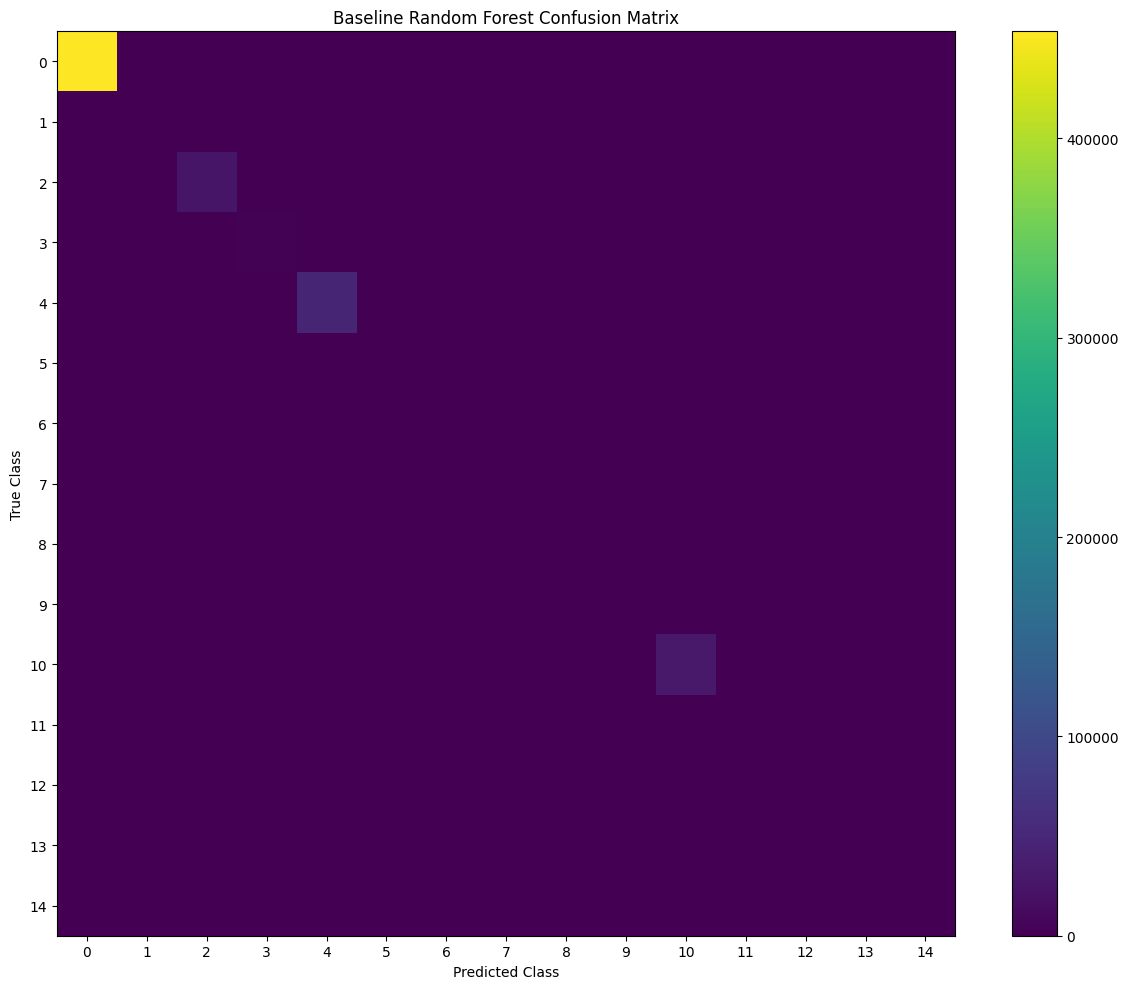


CONFUSION MATRIX GENERATED SUCCESSFULLY


In [43]:
# ============================================================
# Baseline confusion matrix
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

print("=" * 70)
print("BASELINE RANDOM FOREST CONFUSION MATRIX")
print("=" * 70)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=rf_model.classes_
)

print("\nConfusion matrix shape:", cm.shape)
print("Classes:", rf_model.classes_)

print("\nGenerating confusion matrix visualization...")

plt.figure(figsize=(12, 10))

plt.imshow(cm, interpolation="nearest", aspect="auto")
plt.title("Baseline Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.colorbar()

plt.xticks(
    np.arange(len(rf_model.classes_)),
    rf_model.classes_
)

plt.yticks(
    np.arange(len(rf_model.classes_)),
    rf_model.classes_
)

plt.tight_layout()
plt.show()

print("\n" + "=" * 70)
print("CONFUSION MATRIX GENERATED SUCCESSFULLY")
print("=" * 70)

## NORMALIZED CONFUSION MATRIX ANALYSIS

The raw confusion matrix is strongly influenced by the highly dominant Class 0 and therefore does not clearly expose the error patterns of minority classes.

A row-normalized confusion matrix is used to examine prediction behavior relative to the actual samples within each class.

This allows minority-class recall and class-to-class confusion patterns to be compared on the same scale.

The normalized matrix will be used alongside the classification report to identify the classes requiring further investigation.

BASELINE RANDOM FOREST NORMALIZED CONFUSION MATRIX

Each row represents a true class.
Values represent the proportion predicted as each class.


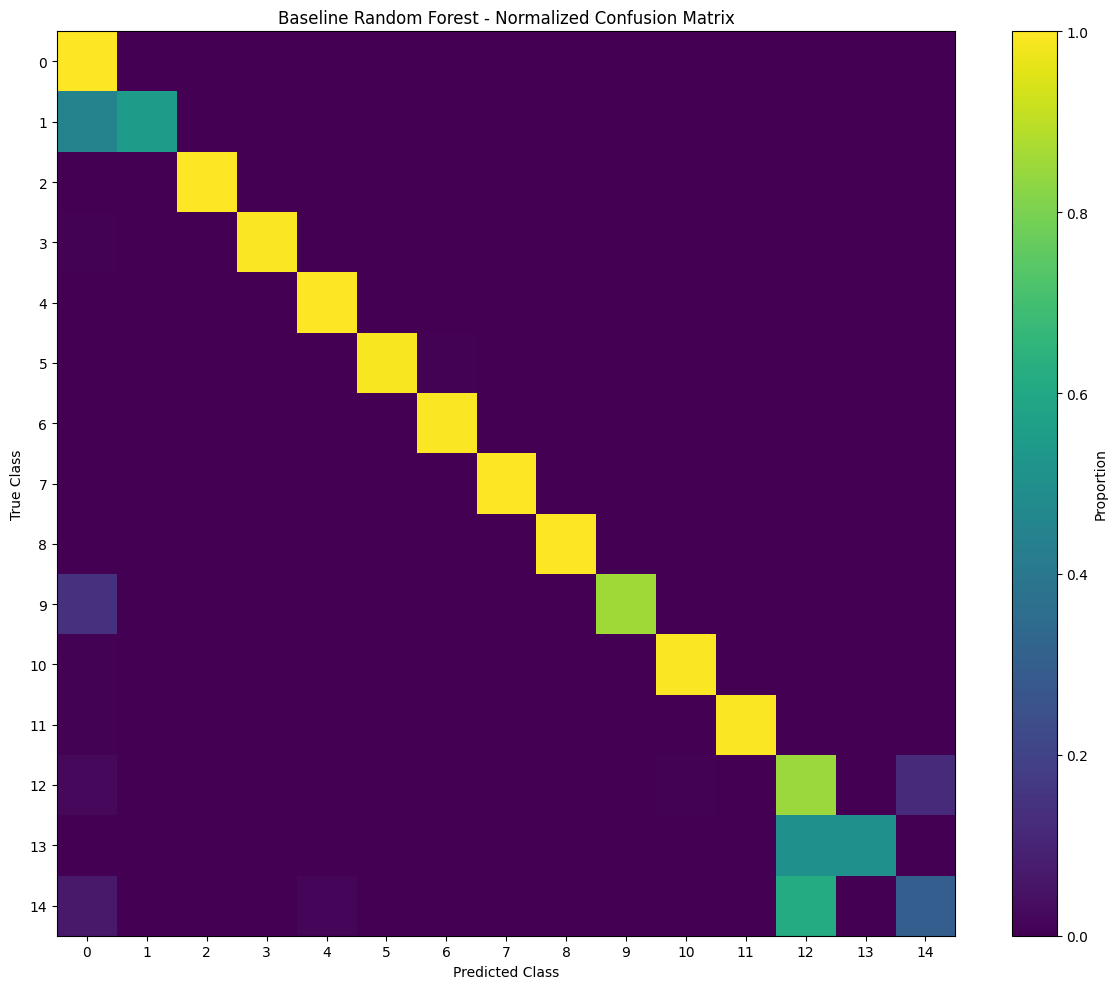


NORMALIZED CONFUSION MATRIX GENERATED SUCCESSFULLY


In [44]:
# ============================================================
# Normalized confusion matrix
# ============================================================

cm_normalized = confusion_matrix(
    y_test,
    y_pred,
    labels=rf_model.classes_,
    normalize="true"
)

print("=" * 70)
print("BASELINE RANDOM FOREST NORMALIZED CONFUSION MATRIX")
print("=" * 70)

print("\nEach row represents a true class.")
print("Values represent the proportion predicted as each class.")

plt.figure(figsize=(12, 10))

plt.imshow(
    cm_normalized,
    interpolation="nearest",
    aspect="auto"
)

plt.title("Baseline Random Forest - Normalized Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.colorbar(label="Proportion")

plt.xticks(
    np.arange(len(rf_model.classes_)),
    rf_model.classes_
)

plt.yticks(
    np.arange(len(rf_model.classes_)),
    rf_model.classes_
)

plt.tight_layout()
plt.show()

print("\n" + "=" * 70)
print("NORMALIZED CONFUSION MATRIX GENERATED SUCCESSFULLY")
print("=" * 70)

In [45]:
# ============================================================
# TOP BASELINE CONFUSION PAIRS
# ============================================================

print("=" * 70)
print("BASELINE RANDOM FOREST - TOP CONFUSION PAIRS")
print("=" * 70)

# Raw confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=rf_model.classes_
)

classes = rf_model.classes_

# Collect only incorrect predictions
confusion_pairs = []

for i, true_class in enumerate(classes):
    for j, predicted_class in enumerate(classes):

        if i != j and cm[i, j] > 0:
            confusion_pairs.append(
                (
                    true_class,
                    predicted_class,
                    cm[i, j]
                )
            )

# Sort by number of errors
confusion_pairs.sort(
    key=lambda x: x[2],
    reverse=True
)

print("\nTop 20 confusion pairs:")
print("-" * 70)
print(f"{'True':<10}{'Predicted':<12}{'Errors':>10}")
print("-" * 70)

for true_class, predicted_class, errors in confusion_pairs[:20]:
    print(
        f"{true_class:<10}"
        f"{predicted_class:<12}"
        f"{errors:>10,}"
    )

print("\n" + "=" * 70)
print("CONFUSION PAIR ANALYSIS COMPLETED")
print("=" * 70)

BASELINE RANDOM FOREST - TOP CONFUSION PAIRS

Top 20 confusion pairs:
----------------------------------------------------------------------
True      Predicted       Errors
----------------------------------------------------------------------
0         4                  505
0         10                 185
1         0                  176
0         1                  146
10        0                  133
0         11                 115
14        12                  80
4         0                   79
12        14                  36
0         14                  15
4         14                  11
2         0                    9
3         0                    9
14        0                    9
11        0                    8
10        4                    7
5         6                    6
12        0                    6
0         5                    4
0         6                    4

CONFUSION PAIR ANALYSIS COMPLETED


## CONTROLLED MODEL IMPROVEMENT EXPERIMENT

The baseline Random Forest uses `class_weight="balanced_subsample"` and demonstrates strong overall performance but weaker recognition of several minority classes.

The baseline error analysis identified Class 1 and Class 14 as the most important minority-class weaknesses, with Class 14 showing substantial confusion with Class 12.

Before performing another full-scale training run, a controlled experiment is conducted on a stratified subset of the training data.

The purpose of this experiment is to investigate whether alternative Random Forest configurations can provide improved macro-level performance and minority-class recognition.

The original test set remains untouched and is reserved for final evaluation. The experiment uses only training data and an internal validation split.

The baseline configuration is retained as the reference configuration.

In [46]:
# ============================================================
# CONTROLLED MODEL IMPROVEMENT - EXPERIMENT DATA
# ============================================================

from sklearn.model_selection import train_test_split

print("=" * 70)
print("CONTROLLED MODEL IMPROVEMENT EXPERIMENT")
print("=" * 70)

EXPERIMENT_SAMPLES = 200_000
MIN_SAMPLES_PER_CLASS = 10

print(f"\nTotal training samples available: {len(y_train):,}")
print(f"Experiment samples requested   : {EXPERIMENT_SAMPLES:,}")

# ------------------------------------------------------------
# Step 1: Identify samples belonging to each class
# ------------------------------------------------------------

unique_classes, class_counts = np.unique(
    y_train,
    return_counts=True
)

print("\nOriginal training class counts:")
for cls, count in zip(unique_classes, class_counts):
    print(f"Class {cls:2d}: {count:,}")

# ------------------------------------------------------------
# Step 2: Guarantee enough samples for every class
# ------------------------------------------------------------

rng = np.random.RandomState(42)

selected_indices = []

for cls in unique_classes:

    class_indices = np.flatnonzero(y_train == cls)

    # Guarantee enough samples for train/validation splitting
    n_select = min(
        MIN_SAMPLES_PER_CLASS,
        len(class_indices)
    )

    selected = rng.choice(
        class_indices,
        size=n_select,
        replace=False
    )

    selected_indices.extend(selected)

selected_indices = np.array(selected_indices)

print("\nGuaranteed minimum samples selected:")
print(f"Samples selected so far: {len(selected_indices):,}")

# ------------------------------------------------------------
# Step 3: Fill remaining samples using random sampling
# ------------------------------------------------------------

remaining_samples = EXPERIMENT_SAMPLES - len(selected_indices)

all_indices = np.arange(len(y_train))

# Exclude already selected samples
available_indices = np.setdiff1d(
    all_indices,
    selected_indices,
    assume_unique=False
)

additional_indices = rng.choice(
    available_indices,
    size=remaining_samples,
    replace=False
)

selected_indices = np.concatenate(
    [selected_indices, additional_indices]
)

# Shuffle final experiment indices
rng.shuffle(selected_indices)

# ------------------------------------------------------------
# Step 4: Create experiment dataset
# ------------------------------------------------------------

X_exp = X_train[selected_indices]
y_exp = y_train[selected_indices]

print("\nExperiment subset created.")
print(f"X_exp shape: {X_exp.shape}")
print(f"y_exp shape: {y_exp.shape}")
print(f"Classes represented: {len(np.unique(y_exp))}")

# ------------------------------------------------------------
# Step 5: Verify class distribution
# ------------------------------------------------------------

exp_classes, exp_counts = np.unique(
    y_exp,
    return_counts=True
)

print("\nExperiment subset class distribution:")
print("-" * 50)

for cls, count in zip(exp_classes, exp_counts):
    print(f"Class {cls:2d}: {count:,}")

# Every class must have at least two samples
if np.min(exp_counts) < 2:
    raise ValueError(
        "Experiment subset contains a class with fewer than 2 samples."
    )

print("\nMinimum class-count check: PASSED")

# ------------------------------------------------------------
# Step 6: Internal validation split
# ------------------------------------------------------------

X_exp_train, X_exp_val, y_exp_train, y_exp_val = train_test_split(
    X_exp,
    y_exp,
    test_size=0.20,
    stratify=y_exp,
    random_state=42
)

print("\nInternal validation split:")
print(f"Training samples  : {len(y_exp_train):,}")
print(f"Validation samples: {len(y_exp_val):,}")

# Verify both splits contain every class
train_classes = np.unique(y_exp_train)
val_classes = np.unique(y_exp_val)

print(f"Training classes  : {len(train_classes)}")
print(f"Validation classes: {len(val_classes)}")

if len(train_classes) != len(unique_classes):
    raise ValueError(
        "Not all classes are represented in experiment training data."
    )

if len(val_classes) != len(unique_classes):
    raise ValueError(
        "Not all classes are represented in experiment validation data."
    )

print("\nClass representation check: PASSED")

print("\n" + "=" * 70)
print("EXPERIMENT DATA PREPARATION COMPLETED SUCCESSFULLY")
print("=" * 70)

CONTROLLED MODEL IMPROVEMENT EXPERIMENT

Total training samples available: 2,264,594
Experiment samples requested   : 200,000

Original training class counts:
Class  0: 1,818,477
Class  1: 1,573
Class  2: 102,421
Class  3: 8,234
Class  4: 184,858
Class  5: 4,399
Class  6: 4,637
Class  7: 6,350
Class  8: 9
Class  9: 29
Class 10: 127,144
Class 11: 4,718
Class 12: 1,206
Class 13: 17
Class 14: 522

Guaranteed minimum samples selected:
Samples selected so far: 149

Experiment subset created.
X_exp shape: (200000, 63)
y_exp shape: (200000,)
Classes represented: 15

Experiment subset class distribution:
--------------------------------------------------
Class  0: 160,370
Class  1: 123
Class  2: 9,132
Class  3: 710
Class  4: 16,455
Class  5: 350
Class  6: 402
Class  7: 584
Class  8: 9
Class  9: 12
Class 10: 11,267
Class 11: 422
Class 12: 102
Class 13: 11
Class 14: 51

Minimum class-count check: PASSED

Internal validation split:
Training samples  : 160,000
Validation samples: 40,000
Training c

## Candidate Random Forest Configuration Experiment

The baseline Random Forest achieved strong overall accuracy but showed a lower
Macro F1 and Macro Recall due to the severe class imbalance in the CICIDS2017
dataset.

Before modifying the full-scale model, a controlled experiment is performed
using the 200,000-sample experimental subset prepared in the previous section.

The experiment evaluates several Random Forest configurations while keeping
the following conditions fixed:

- Same experimental training subset
- Same validation subset
- Same 63 standardized features
- Same 15 target classes
- Same random seed
- Same evaluation metrics

The objective is to determine whether increasing ensemble size, controlling
tree depth, or changing class-weighting strategy provides a meaningful
improvement in minority-class performance.

Macro F1 and Macro Recall are treated as the primary decision metrics because
overall accuracy is strongly influenced by the majority class.

### Candidate Configurations

Four controlled configurations are evaluated:

1. **Baseline configuration**
   - 100 trees
   - `balanced_subsample`
   - Unlimited tree depth

2. **More trees**
   - 150 trees
   - `balanced_subsample`
   - Unlimited tree depth

3. **Controlled tree depth**
   - 100 trees
   - `balanced_subsample`
   - Maximum depth of 20

4. **Balanced class weighting**
   - 100 trees
   - `balanced`
   - Unlimited tree depth

The baseline configuration is included again on the experimental subset so that
all candidates can be compared under exactly the same experimental conditions.

In [47]:
# ============================================================
# CANDIDATE RANDOM FOREST CONFIGURATION EXPERIMENT
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import gc
import time
import pandas as pd

print("=" * 70)
print("CANDIDATE RANDOM FOREST CONFIGURATION EXPERIMENT")
print("=" * 70)

# ------------------------------------------------------------
# Experimental data
# ------------------------------------------------------------

print("\nExperimental training data:")
print(f"Training samples  : {len(y_exp_train):,}")
print(f"Validation samples: {len(y_exp_val):,}")
print(f"Features          : {X_exp_train.shape[1]}")
print(f"Classes           : {len(np.unique(y_exp_train))}")

# ------------------------------------------------------------
# Candidate configurations
# ------------------------------------------------------------

candidate_configs = {
    "baseline": {
        "n_estimators": 100,
        "class_weight": "balanced_subsample",
        "max_features": "sqrt",
        "max_depth": None,
        "min_samples_leaf": 1
    },

    "more_trees": {
        "n_estimators": 150,
        "class_weight": "balanced_subsample",
        "max_features": "sqrt",
        "max_depth": None,
        "min_samples_leaf": 1
    },

    "controlled_depth": {
        "n_estimators": 100,
        "class_weight": "balanced_subsample",
        "max_features": "sqrt",
        "max_depth": 20,
        "min_samples_leaf": 1
    },

    "balanced_weight": {
        "n_estimators": 100,
        "class_weight": "balanced",
        "max_features": "sqrt",
        "max_depth": None,
        "min_samples_leaf": 1
    }
}

print("\nCandidate configurations:")
print("-" * 70)

for name, config in candidate_configs.items():
    print(f"\n{name}")
    for parameter, value in config.items():
        print(f"  {parameter:18s}: {value}")

# ------------------------------------------------------------
# Experiment storage
# ------------------------------------------------------------

experiment_results = []

best_candidate_name = None
best_candidate_score = -np.inf

# ------------------------------------------------------------
# Train and evaluate each candidate
# ------------------------------------------------------------

for candidate_name, config in candidate_configs.items():

    print("\n" + "=" * 70)
    print(f"TRAINING CANDIDATE: {candidate_name.upper()}")
    print("=" * 70)

    print("\nConfiguration:")
    for parameter, value in config.items():
        print(f"{parameter:18s}: {value}")

    start_time = time.time()

    candidate_model = RandomForestClassifier(
        **config,
        n_jobs=-1,
        random_state=42
    )

    print("\nStarting training...")

    candidate_model.fit(
        X_exp_train,
        y_exp_train
    )

    training_time = time.time() - start_time

    print(f"Training completed in {training_time:.2f} seconds.")

    # --------------------------------------------------------
    # Validation prediction
    # --------------------------------------------------------

    prediction_start = time.time()

    y_exp_pred = candidate_model.predict(
        X_exp_val
    )

    prediction_time = time.time() - prediction_start

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_exp_val,
        y_exp_pred
    )

    balanced_accuracy = balanced_accuracy_score(
        y_exp_val,
        y_exp_pred
    )

    macro_precision = precision_score(
        y_exp_val,
        y_exp_pred,
        average="macro",
        zero_division=0
    )

    macro_recall = recall_score(
        y_exp_val,
        y_exp_pred,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_exp_val,
        y_exp_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_exp_val,
        y_exp_pred,
        average="weighted",
        zero_division=0
    )

    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    result = {
        "candidate": candidate_name,
        "n_estimators": config["n_estimators"],
        "max_depth": config["max_depth"],
        "class_weight": config["class_weight"],
        "training_time_sec": training_time,
        "prediction_time_sec": prediction_time,
        "accuracy": accuracy,
        "balanced_accuracy": balanced_accuracy,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1
    }

    experiment_results.append(result)

    # --------------------------------------------------------
    # Display candidate performance
    # --------------------------------------------------------

    print("\nValidation performance:")
    print("-" * 50)
    print(f"Accuracy           : {accuracy:.6f}")
    print(f"Balanced Accuracy  : {balanced_accuracy:.6f}")
    print(f"Macro Precision    : {macro_precision:.6f}")
    print(f"Macro Recall       : {macro_recall:.6f}")
    print(f"Macro F1           : {macro_f1:.6f}")
    print(f"Weighted F1        : {weighted_f1:.6f}")

    # --------------------------------------------------------
    # Select candidate using Macro F1
    # --------------------------------------------------------

    if macro_f1 > best_candidate_score:

        best_candidate_score = macro_f1
        best_candidate_name = candidate_name

        print("\nCurrent best candidate:")
        print(f"  {best_candidate_name}")
        print(f"  Macro F1: {best_candidate_score:.6f}")

    # --------------------------------------------------------
    # Release candidate model and predictions
    # --------------------------------------------------------

    del candidate_model
    del y_exp_pred

    gc.collect()

    print("\nCandidate model released from memory.")

# ------------------------------------------------------------
# Create comparison table
# ------------------------------------------------------------

results_df = pd.DataFrame(
    experiment_results
)

results_df = results_df.sort_values(
    by="macro_f1",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("CANDIDATE MODEL COMPARISON")
print("=" * 70)

print(
    results_df[
        [
            "candidate",
            "n_estimators",
            "max_depth",
            "class_weight",
            "accuracy",
            "balanced_accuracy",
            "macro_precision",
            "macro_recall",
            "macro_f1",
            "weighted_f1",
            "training_time_sec"
        ]
    ].to_string(index=False)
)

print("\n" + "=" * 70)
print("CANDIDATE EXPERIMENT COMPLETED")
print("=" * 70)

print(f"\nBest candidate by Macro F1: {best_candidate_name}")
print(f"Best experimental Macro F1: {best_candidate_score:.6f}")

print("\nPrimary decision metric: Macro F1")
print("Secondary metrics: Macro Recall and Balanced Accuracy")

print("=" * 70)

CANDIDATE RANDOM FOREST CONFIGURATION EXPERIMENT

Experimental training data:
Training samples  : 160,000
Validation samples: 40,000
Features          : 63
Classes           : 15

Candidate configurations:
----------------------------------------------------------------------

baseline
  n_estimators      : 100
  class_weight      : balanced_subsample
  max_features      : sqrt
  max_depth         : None
  min_samples_leaf  : 1

more_trees
  n_estimators      : 150
  class_weight      : balanced_subsample
  max_features      : sqrt
  max_depth         : None
  min_samples_leaf  : 1

controlled_depth
  n_estimators      : 100
  class_weight      : balanced_subsample
  max_features      : sqrt
  max_depth         : 20
  min_samples_leaf  : 1

balanced_weight
  n_estimators      : 100
  class_weight      : balanced
  max_features      : sqrt
  max_depth         : None
  min_samples_leaf  : 1

TRAINING CANDIDATE: BASELINE

Configuration:
n_estimators      : 100
class_weight      : balanced

## Model Selection Decision

The controlled configuration experiment evaluated four Random Forest
configurations on a fixed 200,000-sample experimental subset.

The original baseline configuration achieved the highest Macro F1 among all
tested candidates.

The results show that:

- Increasing the number of trees from 100 to 150 did not improve minority-class
  performance.
- Replacing `balanced_subsample` with `balanced` produced a small decrease in
  Macro F1.
- Restricting the maximum tree depth to 20 substantially reduced Macro F1,
  Balanced Accuracy, and overall Accuracy.
- The baseline configuration therefore provides the strongest performance among
  the tested configurations.

### Selected configuration

The baseline Random Forest is retained:

- Number of trees: 100
- Class weighting: `balanced_subsample`
- Maximum features: `sqrt`
- Maximum depth: unrestricted
- Minimum samples per leaf: 1
- Random state: 42

No additional full-dataset retraining is required because the selected
configuration is identical to the already trained and persisted baseline model.

The previously persisted baseline model will therefore be used for subsequent
analysis and evaluation.

In [48]:
# ============================================================
# PERSIST CONTROLLED MODEL EXPERIMENT RESULTS
# ============================================================

import os
import json
import pandas as pd

print("=" * 70)
print("PERSISTING MODEL SELECTION EXPERIMENT")
print("=" * 70)

# ------------------------------------------------------------
# Output paths
# ------------------------------------------------------------

EXPERIMENT_RESULTS_PATH = os.path.join(
    MODEL_PREP_PATH,
    "random_forest_candidate_experiment.csv"
)

MODEL_SELECTION_PATH = os.path.join(
    MODEL_PREP_PATH,
    "random_forest_model_selection.json"
)

# ------------------------------------------------------------
# Save candidate comparison
# ------------------------------------------------------------

results_df.to_csv(
    EXPERIMENT_RESULTS_PATH,
    index=False
)

# ------------------------------------------------------------
# Save model-selection decision
# ------------------------------------------------------------

model_selection = {
    "selected_model": "baseline",
    "selection_metric": "macro_f1",
    "selected_configuration": candidate_configs["baseline"],
    "experimental_samples": 200000,
    "experimental_training_samples": 160000,
    "experimental_validation_samples": 40000,
    "random_state": 42,
    "decision": (
        "Retain the original baseline Random Forest. "
        "No full-dataset retraining is required because the selected "
        "configuration is identical to the already trained persisted model."
    )
}

with open(MODEL_SELECTION_PATH, "w") as f:
    json.dump(
        model_selection,
        f,
        indent=4
    )

# ------------------------------------------------------------
# Verify persistence
# ------------------------------------------------------------

print("\nExperiment results saved:")
print(f"✓ {EXPERIMENT_RESULTS_PATH}")

print("\nModel selection decision saved:")
print(f"✓ {MODEL_SELECTION_PATH}")

assert os.path.exists(EXPERIMENT_RESULTS_PATH)
assert os.path.exists(MODEL_SELECTION_PATH)

print("\n" + "=" * 70)
print("MODEL SELECTION PERSISTENCE COMPLETED SUCCESSFULLY")
print("=" * 70)

PERSISTING MODEL SELECTION EXPERIMENT

Experiment results saved:
✓ /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/model_preparation/random_forest_candidate_experiment.csv

Model selection decision saved:
✓ /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/model_preparation/random_forest_model_selection.json

MODEL SELECTION PERSISTENCE COMPLETED SUCCESSFULLY


## Experiment Persistence Validation

The controlled Random Forest experiment and the resulting model-selection
decision are persisted to the project output directory.

This ensures that the experimental evidence remains available after the Colab
runtime is disconnected and can be referenced during subsequent model
development and research-paper preparation.

In [49]:
# ============================================================
# VERIFY MODEL SELECTION ARTIFACTS
# ============================================================

print("=" * 70)
print("MODEL SELECTION ARTIFACT VALIDATION")
print("=" * 70)

required_artifacts = [
    EXPERIMENT_RESULTS_PATH,
    MODEL_SELECTION_PATH
]

for artifact in required_artifacts:

    if not os.path.exists(artifact):
        raise FileNotFoundError(
            f"Required artifact not found: {artifact}"
        )

    file_size = os.path.getsize(artifact)

    print(f"✓ {os.path.basename(artifact)}")
    print(f"  Size: {file_size:,} bytes")

print("\nModel selection artifacts verified successfully.")

print("=" * 70)
print("MODEL SELECTION VALIDATION PASSED")
print("=" * 70)

MODEL SELECTION ARTIFACT VALIDATION
✓ random_forest_candidate_experiment.csv
  Size: 869 bytes
✓ random_forest_model_selection.json
  Size: 616 bytes

Model selection artifacts verified successfully.
MODEL SELECTION VALIDATION PASSED


## Minority-Class Error Analysis

The baseline Random Forest achieved very high overall accuracy on the test
dataset. However, the dataset exhibits severe class imbalance, meaning that
overall accuracy alone does not adequately represent performance across all
intrusion classes.

The previous evaluation showed substantially lower performance for several
minority classes despite strong performance on the majority classes.

This section investigates minority-class performance in greater detail.

The analysis will focus on:

- Per-class precision, recall, and F1-score
- Class support
- Classes with the lowest F1-score
- False-negative behavior for minority classes
- Confusion patterns involving minority classes

The purpose is to determine which intrusion classes remain difficult for the
baseline Random Forest and to identify potential limitations of the model.

No additional model training will be performed in this section.

In [50]:
# ============================================================
# MINORITY-CLASS PERFORMANCE ANALYSIS
# ============================================================

print("=" * 70)
print("MINORITY-CLASS PERFORMANCE ANALYSIS")
print("=" * 70)

# Generate per-class metrics
report_dict = classification_report(
    y_test,
    y_pred,
    labels=rf_model.classes_,
    output_dict=True,
    zero_division=0
)

class_rows = []

for class_id in rf_model.classes_:

    metrics = report_dict[str(class_id)]

    class_rows.append({
        "class": int(class_id),
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1_score": metrics["f1-score"],
        "support": int(metrics["support"])
    })

minority_df = pd.DataFrame(class_rows)

# Add class percentage
minority_df["support_percent"] = (
    minority_df["support"] / len(y_test) * 100
)

# Sort by F1 score
minority_df = minority_df.sort_values(
    by="f1_score",
    ascending=True
).reset_index(drop=True)

print("\nClasses ranked by F1-score:")
print("-" * 70)

print(
    minority_df.to_string(
        index=False,
        formatters={
            "precision": "{:.4f}".format,
            "recall": "{:.4f}".format,
            "f1_score": "{:.4f}".format,
            "support_percent": "{:.4f}%".format
        }
    )
)

print("\n" + "=" * 70)
print("MINORITY-CLASS PERFORMANCE ANALYSIS COMPLETED")
print("=" * 70)

MINORITY-CLASS PERFORMANCE ANALYSIS

Classes ranked by F1-score:
----------------------------------------------------------------------
 class precision recall f1_score  support support_percent
    14    0.3824 0.3000   0.3362      130         0.0230%
    13    0.6667 0.5000   0.5714        4         0.0007%
     1    0.5978 0.5522   0.5741      393         0.0694%
    12    0.7485 0.8505   0.7963      301         0.0532%
     9    1.0000 0.8571   0.9231        7         0.0012%
    11    0.9106 0.9932   0.9501     1179         0.2082%
     5    0.9927 0.9918   0.9923     1100         0.1943%
     6    0.9914 0.9948   0.9931     1159         0.2047%
     4    0.9889 0.9979   0.9934    46215         8.1630%
    10    0.9941 0.9955   0.9948    31786         5.6144%
     3    0.9985 0.9937   0.9961     2059         0.3637%
     0    0.9990 0.9979   0.9984   454620        80.3004%
     7    1.0000 0.9994   0.9997     1588         0.2805%
     2    0.9999 0.9996   0.9998    25606         4.

## Minority-Class Error Destination Analysis

The per-class evaluation identified classes 14, 1, and 12 as the most important
minority-class cases requiring further investigation.

Class 13 also shows a low F1-score, but its test support consists of only four
samples. Therefore, its performance is treated cautiously and is not considered
sufficient evidence for a general performance conclusion.

This section examines the prediction destinations of incorrectly classified
samples from the identified minority classes.

The objective is to determine which alternative classes receive the incorrect
predictions and whether specific confusion patterns explain the reduced
minority-class recall.

No additional model training is performed.

In [51]:
# ============================================================
# MINORITY-CLASS ERROR DESTINATION ANALYSIS
# ============================================================

from collections import Counter

print("=" * 70)
print("MINORITY-CLASS ERROR DESTINATION ANALYSIS")
print("=" * 70)

# Classes selected for meaningful investigation
investigation_classes = [14, 1, 12, 13]

for true_class in investigation_classes:

    # Locate all test samples belonging to this true class
    class_mask = (y_test == true_class)

    true_labels = y_test[class_mask]
    predicted_labels = y_pred[class_mask]

    total_samples = len(true_labels)
    correct = np.sum(predicted_labels == true_class)
    incorrect = total_samples - correct

    print(f"\n{'-' * 70}")
    print(f"TRUE CLASS: {true_class}")
    print(f"{'-' * 70}")

    print(f"Total test samples : {total_samples:,}")
    print(f"Correct predictions: {correct:,}")
    print(f"Incorrect predictions: {incorrect:,}")

    if total_samples > 0:
        print(
            f"Observed recall   : "
            f"{correct / total_samples:.4f}"
        )

    if incorrect > 0:

        # Count only incorrect prediction destinations
        error_predictions = predicted_labels[
            predicted_labels != true_class
        ]

        destination_counts = Counter(error_predictions)

        print("\nIncorrect prediction destinations:")
        print("-" * 50)
        print(
            f"{'Predicted Class':<20}"
            f"{'Errors':>10}"
            f"{'Error %':>12}"
        )

        for predicted_class, count in destination_counts.most_common():

            error_percentage = (
                count / incorrect * 100
            )

            print(
                f"{int(predicted_class):<20}"
                f"{count:>10,}"
                f"{error_percentage:>11.2f}%"
            )

print("\n" + "=" * 70)
print("MINORITY-CLASS ERROR DESTINATION ANALYSIS COMPLETED")
print("=" * 70)

MINORITY-CLASS ERROR DESTINATION ANALYSIS

----------------------------------------------------------------------
TRUE CLASS: 14
----------------------------------------------------------------------
Total test samples : 130
Correct predictions: 39
Incorrect predictions: 91
Observed recall   : 0.3000

Incorrect prediction destinations:
--------------------------------------------------
Predicted Class         Errors     Error %
12                          80      87.91%
0                            9       9.89%
4                            2       2.20%

----------------------------------------------------------------------
TRUE CLASS: 1
----------------------------------------------------------------------
Total test samples : 393
Correct predictions: 217
Incorrect predictions: 176
Observed recall   : 0.5522

Incorrect prediction destinations:
--------------------------------------------------
Predicted Class         Errors     Error %
0                          176     100.00%

----

## Random Forest Feature Importance Analysis

The previous error analysis identified concentrated classification difficulties,
particularly between classes 12 and 14 and between class 1 and the majority
class 0.

The next step is to investigate the contribution of the available features to
the selected Random Forest model.

The trained Random Forest provides impurity-based feature importance values,
which quantify the relative contribution of each feature to the reduction of
impurity across the decision trees.

This analysis will:

- Calculate feature importance for all 63 features.
- Rank features by their importance.
- Identify the most influential features.
- Compare the cumulative contribution of the most important features.

This analysis is performed using the already persisted and selected baseline
model. No additional model training is required.

The resulting feature-importance information will be used to guide subsequent
interpretation and model-improvement decisions.

The feature names are recovered from the persisted feature_metadata.json using the feature_columns field, which preserves the original feature ordering used during model preparation. The Random Forest feature-importance values are then mapped to these feature names and validated against the model's 63 input features.

In [63]:
# ============================================================
# CORRECT FEATURE IMPORTANCE MAPPING
# ============================================================

print("=" * 70)
print("CORRECT FEATURE IMPORTANCE MAPPING")
print("=" * 70)

# ------------------------------------------------------------
# Load original feature names from persisted metadata
# ------------------------------------------------------------

FEATURE_METADATA_PATH = os.path.join(
    MODEL_PREP_PATH,
    "feature_metadata.json"
)

with open(FEATURE_METADATA_PATH, "r") as f:
    feature_metadata = json.load(f)

# ------------------------------------------------------------
# Recover the actual feature-to-index mapping
# ------------------------------------------------------------

if "feature_columns" not in feature_metadata:
    raise KeyError(
        "Expected 'feature_columns' key was not found "
        "in feature_metadata.json"
    )

feature_names = feature_metadata["feature_columns"]

# ------------------------------------------------------------
# Validate feature mapping
# ------------------------------------------------------------

assert len(feature_names) == rf_model.n_features_in_, (
    f"Feature count mismatch: "
    f"{len(feature_names)} metadata names vs "
    f"{rf_model.n_features_in_} model features"
)

# ------------------------------------------------------------
# Extract Random Forest feature importance
# ------------------------------------------------------------

feature_importances = rf_model.feature_importances_

assert len(feature_importances) == len(feature_names), (
    "Feature importance and feature metadata lengths do not match."
)

# ------------------------------------------------------------
# Create correctly mapped importance table
# ------------------------------------------------------------

feature_importance_df = pd.DataFrame({
    "feature_index": np.arange(len(feature_names)),
    "feature": feature_names,
    "importance": feature_importances
})

feature_importance_df = feature_importance_df.sort_values(
    by="importance",
    ascending=False
).reset_index(drop=True)

# Rank
feature_importance_df.insert(
    0,
    "rank",
    np.arange(1, len(feature_importance_df) + 1)
)

# Cumulative importance
feature_importance_df["cumulative_importance"] = (
    feature_importance_df["importance"].cumsum()
)

# ------------------------------------------------------------
# Display complete ranking
# ------------------------------------------------------------

print("\nFeature importance ranking:")
print("-" * 90)

print(
    feature_importance_df.to_string(
        index=False,
        formatters={
            "importance": "{:.6f}".format,
            "cumulative_importance": "{:.6f}".format
        }
    )
)

# ------------------------------------------------------------
# Display top 15 features
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TOP 15 MOST IMPORTANT FEATURES")
print("=" * 70)

print(
    feature_importance_df[
        [
            "rank",
            "feature_index",
            "feature",
            "importance",
            "cumulative_importance"
        ]
    ].head(15).to_string(
        index=False,
        formatters={
            "importance": "{:.6f}".format,
            "cumulative_importance": "{:.6f}".format
        }
    )
)

print("\n" + "=" * 70)
print("FEATURE IMPORTANCE MAPPING COMPLETED SUCCESSFULLY")
print("=" * 70)

CORRECT FEATURE IMPORTANCE MAPPING

Feature importance ranking:
------------------------------------------------------------------------------------------
 rank  feature_index                     feature importance cumulative_importance
    1              0            Destination Port   0.084236              0.084236
    2             35               Bwd Packets/s   0.035648              0.119884
    3             16               Flow IAT Mean   0.032345              0.152229
    4             52           Subflow Bwd Bytes   0.028656              0.180885
    5             15              Flow Packets/s   0.027870              0.208755
    6             50        Avg Bwd Segment Size   0.026332              0.235087
    7             51           Subflow Fwd Bytes   0.025310              0.260398
    8             54        min_seg_size_forward   0.025167              0.285565
    9             33           Bwd Header Length   0.024797              0.310362
   10              1     

In [64]:
# ============================================================
# PERSIST FEATURE IMPORTANCE ANALYSIS
# ============================================================

print("=" * 70)
print("PERSISTING FEATURE IMPORTANCE ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Output paths
# ------------------------------------------------------------

FEATURE_IMPORTANCE_PATH = os.path.join(
    MODELS_PATH,
    "random_forest_feature_importance.csv"
)

FEATURE_IMPORTANCE_METADATA_PATH = os.path.join(
    MODELS_PATH,
    "random_forest_feature_importance_metadata.json"
)

# ------------------------------------------------------------
# Save complete feature-importance ranking
# ------------------------------------------------------------

feature_importance_df.to_csv(
    FEATURE_IMPORTANCE_PATH,
    index=False
)

# ------------------------------------------------------------
# Create feature-importance metadata
# ------------------------------------------------------------

feature_importance_metadata = {
    "model": "RandomForestClassifier",
    "model_file": "random_forest_baseline.joblib",
    "number_of_features": int(rf_model.n_features_in_),
    "importance_type": "impurity_based",
    "feature_metadata_source": "feature_metadata.json",
    "feature_mapping_key": "feature_columns",
    "random_state": int(rf_model.random_state),
    "n_estimators": int(rf_model.n_estimators)
}

with open(
    FEATURE_IMPORTANCE_METADATA_PATH,
    "w"
) as f:
    json.dump(
        feature_importance_metadata,
        f,
        indent=4
    )

# ------------------------------------------------------------
# Verify persistence
# ------------------------------------------------------------

assert os.path.exists(FEATURE_IMPORTANCE_PATH)
assert os.path.exists(FEATURE_IMPORTANCE_METADATA_PATH)

print("\nFeature importance files saved successfully:")

print(
    f"✓ {FEATURE_IMPORTANCE_PATH}"
)

print(
    f"✓ {FEATURE_IMPORTANCE_METADATA_PATH}"
)

print("\nSaved feature count:",
      len(feature_importance_df))

print("\nTop feature:")
print(
    feature_importance_df.iloc[0]["feature"]
)

print(
    "Top feature importance:",
    f"{feature_importance_df.iloc[0]['importance']:.6f}"
)

print("\n" + "=" * 70)
print("FEATURE IMPORTANCE PERSISTENCE COMPLETED")
print("=" * 70)

PERSISTING FEATURE IMPORTANCE ANALYSIS

Feature importance files saved successfully:
✓ /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/trained_models/random_forest_feature_importance.csv
✓ /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/trained_models/random_forest_feature_importance_metadata.json

Saved feature count: 63

Top feature:
Destination Port
Top feature importance: 0.084236

FEATURE IMPORTANCE PERSISTENCE COMPLETED


In [65]:
# ============================================================
# FINAL MODEL HANDOFF VALIDATION
# ============================================================

print("=" * 70)
print("FINAL RANDOM FOREST MODEL HANDOFF VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

FINAL_MODEL_PATH = os.path.join(
    MODELS_PATH,
    "random_forest_baseline.joblib"
)

FEATURE_METADATA_PATH = os.path.join(
    MODEL_PREP_PATH,
    "feature_metadata.json"
)

FEATURE_IMPORTANCE_PATH = os.path.join(
    MODELS_PATH,
    "random_forest_feature_importance.csv"
)

FEATURE_IMPORTANCE_METADATA_PATH = os.path.join(
    MODELS_PATH,
    "random_forest_feature_importance_metadata.json"
)

MODEL_SELECTION_PATH = os.path.join(
    MODEL_PREP_PATH,
    "random_forest_model_selection.json"
)

# ------------------------------------------------------------
# Check required files
# ------------------------------------------------------------

required_files = {
    "Random Forest model": FINAL_MODEL_PATH,
    "Feature metadata": FEATURE_METADATA_PATH,
    "Feature importance": FEATURE_IMPORTANCE_PATH,
    "Feature importance metadata": FEATURE_IMPORTANCE_METADATA_PATH,
    "Model selection metadata": MODEL_SELECTION_PATH
}

print("\nREQUIRED ARTIFACT CHECK")
print("-" * 70)

all_files_present = True

for name, path in required_files.items():

    exists = os.path.exists(path)

    print(
        f"{name:<30}: "
        f"{'PRESENT' if exists else 'MISSING'}"
    )

    if not exists:
        all_files_present = False

# ------------------------------------------------------------
# Load persisted model
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("LOADING PERSISTED MODEL")
print("-" * 70)

if not os.path.exists(FINAL_MODEL_PATH):
    raise FileNotFoundError(
        f"Persisted Random Forest model not found:\n{FINAL_MODEL_PATH}"
    )

final_rf_model = joblib.load(FINAL_MODEL_PATH)

print("Model loaded successfully.")
print("Model type:", type(final_rf_model).__name__)

# ------------------------------------------------------------
# Load feature metadata
# ------------------------------------------------------------

with open(FEATURE_METADATA_PATH, "r") as f:
    final_feature_metadata = json.load(f)

feature_columns = final_feature_metadata["feature_columns"]

print("\nFEATURE METADATA")
print("-" * 70)
print("Dataset:", final_feature_metadata["dataset"])
print("Number of features:", len(feature_columns))
print("Target column:", final_feature_metadata["target_column"])

# ------------------------------------------------------------
# Validate model structure
# ------------------------------------------------------------

print("\nMODEL STRUCTURE VALIDATION")
print("-" * 70)

print(
    "Model feature count:",
    final_rf_model.n_features_in_
)

print(
    "Number of trees:",
    final_rf_model.n_estimators
)

print(
    "Random state:",
    final_rf_model.random_state
)

print(
    "Number of classes:",
    len(final_rf_model.classes_)
)

# ------------------------------------------------------------
# Cross-check model and metadata
# ------------------------------------------------------------

assert (
    final_rf_model.n_features_in_
    == len(feature_columns)
), "Model feature count does not match feature metadata."

print(
    "\n✓ Model feature count matches feature metadata."
)

# ------------------------------------------------------------
# Validate feature importance persistence
# ------------------------------------------------------------

final_feature_importance = pd.read_csv(
    FEATURE_IMPORTANCE_PATH
)

print("\nFEATURE IMPORTANCE VALIDATION")
print("-" * 70)

print(
    "Feature importance rows:",
    len(final_feature_importance)
)

assert (
    len(final_feature_importance)
    == len(feature_columns)
), "Feature importance count does not match feature metadata."

print(
    "Top feature:",
    final_feature_importance.iloc[0]["feature"]
)

print(
    "Top importance:",
    f"{final_feature_importance.iloc[0]['importance']:.6f}"
)

print(
    "\n✓ Feature importance mapping validated."
)

# ------------------------------------------------------------
# Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)

if all_files_present:
    print("FINAL MODEL HANDOFF VALIDATION: SUCCESS")
    print("=" * 70)

    print("\nNotebook 05 Random Forest model is ready for downstream use.")

else:
    print("FINAL MODEL HANDOFF VALIDATION: INCOMPLETE")
    print("=" * 70)

    print(
        "\nOne or more required artifacts are missing."
    )

FINAL RANDOM FOREST MODEL HANDOFF VALIDATION

REQUIRED ARTIFACT CHECK
----------------------------------------------------------------------
Random Forest model           : PRESENT
Feature metadata              : PRESENT
Feature importance            : PRESENT
Feature importance metadata   : PRESENT
Model selection metadata      : PRESENT

----------------------------------------------------------------------
LOADING PERSISTED MODEL
----------------------------------------------------------------------
Model loaded successfully.
Model type: RandomForestClassifier

FEATURE METADATA
----------------------------------------------------------------------
Dataset: CICIDS2017
Number of features: 63
Target column: Target

MODEL STRUCTURE VALIDATION
----------------------------------------------------------------------
Model feature count: 63
Number of trees: 100
Random state: 42
Number of classes: 15

✓ Model feature count matches feature metadata.

FEATURE IMPORTANCE VALIDATION
-------------

In [71]:
# ============================================================
# NOTEBOOK 05 - RANDOM FOREST MODEL HANDOFF BUNDLE
# ============================================================

import os
import json
import joblib
import pickle

print("=" * 70)
print("RANDOM FOREST MODEL HANDOFF BUNDLE")
print("=" * 70)

# ------------------------------------------------------------
# 1. VERIFY EXISTING RANDOM FOREST MODEL
# ------------------------------------------------------------

print("\nExisting model:")
print(MODEL_PATH)

if not os.path.isfile(MODEL_PATH):
    raise FileNotFoundError(
        f"Random Forest model not found:\n{MODEL_PATH}"
    )

# Load the already-trained Random Forest
rf_handoff_model = joblib.load(MODEL_PATH)

print("✓ Random Forest model loaded successfully.")
print(f"Model type: {type(rf_handoff_model).__name__}")


# ------------------------------------------------------------
# 2. RECOVER FEATURE NAMES
# ------------------------------------------------------------

# The Random Forest was trained using a NumPy array,
# therefore feature_names_in_ may not exist.
#
# We already persisted the feature-importance mapping earlier
# in Notebook 05, so use that as the authoritative feature order.

if "feature_importance_df" in globals():

    feature_names = feature_importance_df["feature"].tolist()

elif os.path.isfile(FEATURE_IMPORTANCE_PATH):

    feature_importance_df = pd.read_csv(FEATURE_IMPORTANCE_PATH)
    feature_names = feature_importance_df["feature"].tolist()

else:

    raise FileNotFoundError(
        "Feature importance mapping could not be found."
    )


print(f"Feature mapping recovered successfully.")
print(f"Number of features: {len(feature_names)}")

if len(feature_names) != rf_handoff_model.n_features_in_:
    raise ValueError(
        f"Feature count mismatch: "
        f"mapping has {len(feature_names)} features, "
        f"but Random Forest expects "
        f"{rf_handoff_model.n_features_in_}."
    )

print("✓ Feature count matches Random Forest model.")


# ------------------------------------------------------------
# 3. DEFINE HANDOFF FILE PATHS
# ------------------------------------------------------------

# IMPORTANT:
# Use the existing MODEL_PATH/trained_models directory.
# Do NOT use TRAINED_MODEL_PATH because that variable
# does not exist in this notebook.

TRAINED_MODELS_DIR = os.path.dirname(MODEL_PATH)

RF_HANDOFF_PATH = os.path.join(
    TRAINED_MODELS_DIR,
    "random_forest_handoff.joblib"
)

RF_HANDOFF_PKL_PATH = os.path.join(
    TRAINED_MODELS_DIR,
    "random_forest_handoff.pkl"
)


# ------------------------------------------------------------
# 4. BUILD HANDOFF BUNDLE
# ------------------------------------------------------------

rf_handoff_bundle = {
    "model": rf_handoff_model,
    "feature_names": feature_names,
    "n_features": len(feature_names),
    "n_classes": len(rf_handoff_model.classes_),
    "model_type": type(rf_handoff_model).__name__,
    "dataset": "CICIDS2017",
    "target_column": "Target",
}


# ------------------------------------------------------------
# 5. SAVE JOBLIB HANDOFF BUNDLE
# ------------------------------------------------------------

joblib.dump(
    rf_handoff_bundle,
    RF_HANDOFF_PATH
)

print("\n✓ Joblib handoff bundle saved:")
print(RF_HANDOFF_PATH)


# ------------------------------------------------------------
# 6. ALSO SAVE PICKLE VERSION
# ------------------------------------------------------------

with open(RF_HANDOFF_PKL_PATH, "wb") as f:
    pickle.dump(
        rf_handoff_bundle,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )

print("✓ Pickle handoff bundle saved:")
print(RF_HANDOFF_PKL_PATH)


# ------------------------------------------------------------
# 7. VERIFY FILES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("HANDOFF FILE VALIDATION")
print("=" * 70)

for path in [RF_HANDOFF_PATH, RF_HANDOFF_PKL_PATH]:

    if os.path.isfile(path):

        size_mb = os.path.getsize(path) / (1024 * 1024)

        print(f"✓ {os.path.basename(path)}")
        print(f"  Size: {size_mb:.2f} MB")

    else:

        print(f"✗ Missing: {path}")


# ------------------------------------------------------------
# 8. TEST LOAD THE JOBLIB BUNDLE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("HANDOFF BUNDLE LOAD TEST")
print("=" * 70)

loaded_bundle = joblib.load(RF_HANDOFF_PATH)

assert "model" in loaded_bundle
assert "feature_names" in loaded_bundle
assert loaded_bundle["n_features"] == 63
assert len(loaded_bundle["feature_names"]) == 63
assert loaded_bundle["model"].n_features_in_ == 63

print("✓ Handoff bundle loaded successfully.")
print("✓ Model structure validated.")
print("✓ Feature mapping validated.")
print("✓ 63 features confirmed.")
print("✓ Random Forest is ready for downstream integration.")

print("\n" + "=" * 70)
print("RANDOM FOREST HANDOFF COMPLETED SUCCESSFULLY")
print("=" * 70)

RANDOM FOREST MODEL HANDOFF BUNDLE

Existing model:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/trained_models/random_forest_baseline.joblib
✓ Random Forest model loaded successfully.
Model type: RandomForestClassifier
Feature mapping recovered successfully.
Number of features: 63
✓ Feature count matches Random Forest model.

✓ Joblib handoff bundle saved:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/trained_models/random_forest_handoff.joblib
✓ Pickle handoff bundle saved:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/trained_models/random_forest_handoff.pkl

HANDOFF FILE VALIDATION
✓ random_forest_handoff.joblib
  Size: 187.18 MB
✓ random_forest_handoff.pkl
  Size: 187.17 MB

HANDOFF BUNDLE LOAD TEST
✓ Handoff bundle loaded successfully.
✓ Model structure validated.
✓ Feature mapping validated.
✓ 63 features confirmed.
✓ Random Forest is ready for downstream integration.

RANDOM FOREST HANDOFF COMPLETED SUCCESSFULLY


In [ ]:
# ============================================================
# NOTEBOOK 05 - FINAL ARTIFACT INVENTORY
# ============================================================

import os

print("=" * 70)
print("NOTEBOOK 05 - FINAL ARTIFACT INVENTORY")
print("=" * 70)

print("\nTrained model directory:")
print(MODELS_PATH)

if not os.path.exists(MODELS_PATH):
    raise FileNotFoundError(
        f"Trained model directory not found:\n{MODELS_PATH}"
    )

print("\nFiles currently saved:")

for filename in sorted(os.listdir(MODELS_PATH)):

    filepath = os.path.join(
        MODELS_PATH,
        filename
    )

    if os.path.isfile(filepath):

        size_mb = os.path.getsize(filepath) / (1024 * 1024)

        print(
            f"  ✓ {filename:<50} "
            f"{size_mb:.2f} MB"
        )

print("\n" + "=" * 70)
print("MODEL FILE CHECK")
print("=" * 70)

if os.path.isfile(MODEL_PATH):

    model_size_mb = os.path.getsize(MODEL_PATH) / (1024 * 1024)

    print("✓ Random Forest model found")
    print(f"  File: {os.path.basename(MODEL_PATH)}")
    print(f"  Size: {model_size_mb:.2f} MB")

else:

    raise FileNotFoundError(
        f"Random Forest model not found:\n{MODEL_PATH}"
    )

print("\n" + "=" * 70)
print("ARTIFACT INVENTORY COMPLETED SUCCESSFULLY")
print("=" * 70)

NOTEBOOK 05 - FINAL ARTIFACT INVENTORY

Trained model directory:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/trained_models

Files currently saved:
  ✓ random_forest_baseline.joblib                      28.48 MB
  ✓ random_forest_feature_importance.csv               0.00 MB
  ✓ random_forest_feature_importance_metadata.json     0.00 MB

MODEL FILE CHECK
✓ Random Forest model found
  File: random_forest_baseline.joblib
  Size: 28.48 MB

ARTIFACT INVENTORY COMPLETED SUCCESSFULLY


In [73]:
# ============================================================
# NOTEBOOK 05 - FINAL HANDOFF INFERENCE TEST
# ============================================================

print("=" * 70)
print("FINAL RANDOM FOREST HANDOFF INFERENCE TEST")
print("=" * 70)

# Load handoff bundle from disk
final_bundle = joblib.load(RF_HANDOFF_PATH)

final_rf_model = final_bundle["model"]
final_feature_names = final_bundle["feature_names"]

# Validate feature structure
assert len(final_feature_names) == final_rf_model.n_features_in_
assert final_rf_model.n_features_in_ == X_test.shape[1]

# Use one test sample
sample = X_test[:1]

# Generate prediction
prediction = final_rf_model.predict(sample)

print("\n✓ Handoff bundle loaded successfully.")
print(f"✓ Number of features: {len(final_feature_names)}")
print(f"✓ Test sample shape: {sample.shape}")
print(f"✓ Prediction generated: {prediction[0]}")

if hasattr(final_rf_model, "predict_proba"):
    probabilities = final_rf_model.predict_proba(sample)
    confidence = probabilities.max()

    print(f"✓ Prediction confidence: {confidence:.6f}")

print("\n" + "=" * 70)
print("FINAL HANDOFF INFERENCE TEST PASSED")
print("=" * 70)

print("\nRandom Forest model is fully ready for downstream integration.")
print("Notebook 05 completed successfully.")

FINAL RANDOM FOREST HANDOFF INFERENCE TEST

✓ Handoff bundle loaded successfully.
✓ Number of features: 63
✓ Test sample shape: (1, 63)
✓ Prediction generated: 0
✓ Prediction confidence: 1.000000

FINAL HANDOFF INFERENCE TEST PASSED

Random Forest model is fully ready for downstream integration.
Notebook 05 completed successfully.
